# 01 — Retail Decision Intelligence: Exploratory Data Analysis

**Dataset:** Retail Decision Intelligence Dataset V2  
**Scope:** Bengaluru, Chennai and Coimbatore | 20 stores | 100 SKUs | 365 days  
**Purpose:** Understand data quality, retail demand, inventory, wastage, suppliers and external signals before building forecasting models and AI agents.

> Important: `demand_units` represents latent/unconstrained demand in this synthetic dataset, while `quantity` represents fulfilled sales. They are not interchangeable, especially during stockouts.

## 0. How to use this notebook

1. Keep this notebook in the same parent directory as the extracted `retail_decision_intelligence_v2` folder, **or** update `DATA_DIR` below.
2. Run the notebook from top to bottom.
3. Install missing packages if needed: `pip install pandas numpy matplotlib seaborn scipy`.
4. Do not use the test period to make modelling or feature-engineering decisions. The test split is reserved for final evaluation.

In [2]:
# If needed, install dependencies in a notebook cell:
# %pip install pandas numpy matplotlib seaborn scipy

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)

sns.set_theme()  # Uses the standard seaborn theme; change if you prefer.

## 1. Locate and load the dataset

In [3]:
# Update this path if your dataset folder is stored elsewhere.
CANDIDATE_DIRS = [
    Path("Datasets"),
    Path("../retail_decision_intelligence_v2"),
    Path("/mnt/data/retail_decision_intelligence_v2"),
]

DATA_DIR = next((p.resolve() for p in CANDIDATE_DIRS if p.exists()), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find 'retail_decision_intelligence_v2'. "
        "Extract retail_decision_intelligence_dataset_v2.zip and set DATA_DIR to the extracted folder."
    )

print("Dataset directory:", DATA_DIR)

def read_csv(relative_path, parse_dates=None):
    path = DATA_DIR / relative_path
    if not path.exists():
        print(f"[Missing optional file] {relative_path}")
        return pd.DataFrame()

    # Only parse date columns that actually exist in this CSV.
    # This prevents pandas from raising a ValueError when a file uses
    # a name such as event_date instead of date.
    available_columns = pd.read_csv(path, nrows=0).columns.tolist()
    valid_date_columns = [c for c in (parse_dates or []) if c in available_columns]
    missing_date_columns = [c for c in (parse_dates or []) if c not in available_columns]

    if missing_date_columns:
        print(f"[Info] {relative_path}: date column(s) not present and skipped: {missing_date_columns}")

    return pd.read_csv(path, parse_dates=valid_date_columns)

stores = read_csv("master/stores.csv")
products = read_csv("master/products.csv")
suppliers = read_csv("master/suppliers.csv")
supplier_product_map = read_csv("master/supplier_product_map.csv")
assortment = read_csv("master/store_assortment.csv")

sales = read_csv("historical/sales_daily.csv", parse_dates=["date"])
promotions = read_csv("historical/promotions.csv", parse_dates=["start_date", "end_date"])
events = read_csv("historical/events.csv", parse_dates=["event_date"])
weather = read_csv("historical/weather_daily.csv", parse_dates=["date"])
competitor_prices = read_csv("historical/competitor_prices_daily.csv", parse_dates=["date"])
purchase_orders = read_csv("historical/purchase_orders.csv")
goods_receipts = read_csv("historical/goods_receipts.csv")
wastage = read_csv("historical/wastage.csv", parse_dates=["date"])

inventory = read_csv("operational/inventory_snapshot.csv", parse_dates=["snapshot_date"])
transfers = read_csv("operational/inventory_transfers.csv", parse_dates=["transfer_date"])
price_history = read_csv("operational/price_history_weekly.csv", parse_dates=["date"])

news = read_csv("external_signals/news_signals_synthetic.csv", parse_dates=["published_at"])
news_mapping = read_csv("external_signals/news_to_demand_mapping.csv")
scenarios = read_csv("simulation/surprise_scenarios.csv")

split_manifest = read_csv("evaluation/chronological_split_manifest.csv")
baseline_policies = read_csv("evaluation/baseline_policies.csv")

tables = {
    "stores": stores, "products": products, "suppliers": suppliers,
    "supplier_product_map": supplier_product_map, "assortment": assortment,
    "sales": sales, "promotions": promotions, "events": events,
    "weather": weather, "competitor_prices": competitor_prices,
    "purchase_orders": purchase_orders, "goods_receipts": goods_receipts,
    "wastage": wastage, "inventory": inventory, "transfers": transfers,
    "price_history": price_history, "news": news,
    "news_mapping": news_mapping, "scenarios": scenarios,
}

print("\nLoaded tables:")
for name, df in tables.items():
    print(f"{name:22s} {df.shape}")

Dataset directory: D:\TCS AI\Datasets

Loaded tables:
stores                 (20, 11)
products               (100, 16)
suppliers              (20, 10)
supplier_product_map   (200, 4)
assortment             (2000, 4)
sales                  (658825, 21)
promotions             (240, 8)
events                 (33, 8)
weather                (1095, 7)
competitor_prices      (109500, 6)
purchase_orders        (40602, 14)
goods_receipts         (40113, 7)
wastage                (28472, 6)
inventory              (1805, 11)
transfers              (500, 12)
price_history          (15900, 6)
news                   (105, 16)
news_mapping           (7, 3)
scenarios              (8, 6)


## 2. Dataset overview and metadata

In [4]:
metadata_path = DATA_DIR / "documentation/dataset_metadata.json"
quality_path = DATA_DIR / "documentation/data_quality_report.json"

if metadata_path.exists():
    metadata = json.loads(metadata_path.read_text())
    print("Dataset metadata:")
    print(json.dumps(metadata, indent=2)[:8000])

if quality_path.exists():
    quality_report = json.loads(quality_path.read_text())
    print("\nData quality report:")
    print(json.dumps(quality_report, indent=2)[:8000])

print("\nCore dimensions")
overview = pd.DataFrame({
    "metric": ["Cities", "Stores", "Products/SKUs", "Suppliers", "Sales rows",
               "Sales start", "Sales end", "Store-SKU assortment pairs"],
    "value": [
        stores["city"].nunique() if "city" in stores else np.nan,
        len(stores), len(products), len(suppliers), len(sales),
        sales["date"].min() if "date" in sales else None,
        sales["date"].max() if "date" in sales else None,
        len(assortment)
    ]
})
display(overview)


Core dimensions


,metric,value
0,Cities,NaN
1,Stores,20
2,Products/SKUs,100
3,Suppliers,20
4,Sales rows,658825
5,Sales start,2025-11-01 00:00:00
6,Sales end,2026-10-31 00:00:00
7,Store-SKU assortment pairs,2000


## 3. Data quality assessment

In [5]:
def quality_summary(df, name):
    if df.empty:
        return {"table": name, "rows": 0, "columns": 0, "duplicate_rows": 0,
                "missing_cells": 0, "missing_pct": 0.0}
    total_cells = df.shape[0] * df.shape[1]
    missing_cells = int(df.isna().sum().sum())
    return {
        "table": name,
        "rows": len(df),
        "columns": df.shape[1],
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": missing_cells,
        "missing_pct": round(100 * missing_cells / total_cells, 3) if total_cells else 0
    }

quality = pd.DataFrame([quality_summary(df, name) for name, df in tables.items()])
display(quality.sort_values(["missing_pct", "duplicate_rows"], ascending=False))

# Missing-value profile for the main fact table
if not sales.empty:
    missing_sales = sales.isna().mean().mul(100).sort_values(ascending=False)
    display(missing_sales[missing_sales > 0].rename("missing_pct").to_frame())

# Check key uniqueness where expected
key_checks = []
for name, df, keys in [
    ("stores", stores, ["store_id"]),
    ("products", products, ["sku_id"]),
    ("suppliers", suppliers, ["supplier_id"]),
    ("sales", sales, ["date", "store_id", "sku_id"]),
]:
    if not df.empty and all(k in df.columns for k in keys):
        key_checks.append({
            "table": name,
            "key": " + ".join(keys),
            "duplicate_key_rows": int(df.duplicated(keys).sum())
        })
display(pd.DataFrame(key_checks))

,table,rows,columns,duplicate_rows,missing_cells,missing_pct
10,purchase_orders,40602,14,0,489,0.086
0,stores,20,11,0,0,0.000
1,products,100,16,0,0,0.000
2,suppliers,20,10,0,0,0.000
3,supplier_product_map,200,4,0,0,0.000
4,assortment,2000,4,0,0,0.000
5,sales,658825,21,0,0,0.000
6,promotions,240,8,0,0,0.000
7,events,33,8,0,0,0.000
8,weather,1095,7,0,0,0.000


,missing_pct


,table,key,duplicate_key_rows
0,stores,store_id,0
1,products,sku_id,0
2,suppliers,supplier_id,0
3,sales,date + store_id + sku_id,0


### 3.1 Referential integrity checks

In [6]:
def unmatched_values(child, child_col, parent, parent_col, label):
    if child.empty or parent.empty or child_col not in child or parent_col not in parent:
        return {"relationship": label, "unmatched_count": np.nan}
    return {
        "relationship": label,
        "unmatched_count": int((~child[child_col].isin(parent[parent_col])).sum())
    }

refs = [
    unmatched_values(sales, "store_id", stores, "store_id", "sales.store_id → stores.store_id"),
    unmatched_values(sales, "sku_id", products, "sku_id", "sales.sku_id → products.sku_id"),
    unmatched_values(purchase_orders, "supplier_id", suppliers, "supplier_id", "purchase_orders.supplier_id → suppliers.supplier_id"),
]
display(pd.DataFrame(refs))

,relationship,unmatched_count
0,sales.store_id → stores.store_id,0
1,sales.sku_id → products.sku_id,0
2,purchase_orders.supplier_id → suppliers.suppli...,0


## 4. City-wise and store-wise retail profile

CITY-WISE RETAIL PERFORMANCE


,city,fulfilled_units,demand_units,revenue,gross_profit,lost_sales_units,store_count
0,Bangalore,198951,242060,13728622.10,3353618.46,43109,8
1,Chennai,189346,231429,12795742.14,3105478.07,42083,7
2,Coimbatore,117617,142697,8055176.35,1955019.97,25080,5


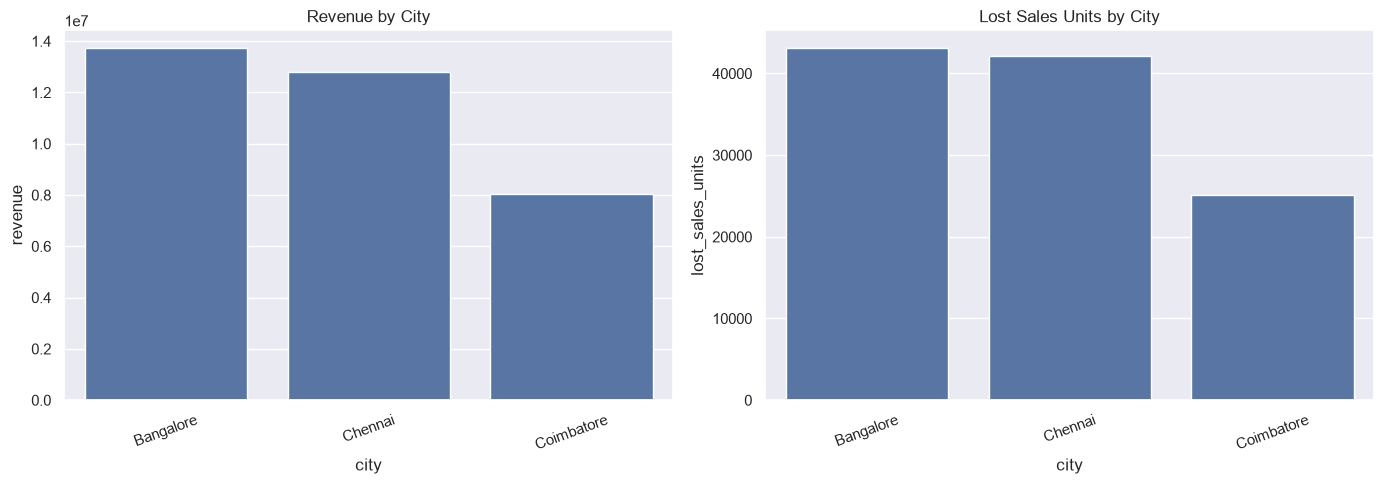

TOP 15 STORES BY REVENUE


,city,store_id,revenue,fulfilled_units,lost_sales
13,Chennai,ST014,2002818.07,30130,6696
8,Chennai,ST009,1992882.07,30314,7052
10,Chennai,ST011,1958876.83,29061,6775
11,Chennai,ST012,1887862.46,26212,5971
7,Bangalore,ST008,1873552.71,27064,6128
5,Bangalore,ST006,1867967.91,28003,6050
0,Bangalore,ST001,1865027.82,26564,5802
15,Coimbatore,ST016,1847977.41,26847,5685
2,Bangalore,ST003,1841129.73,26138,5830
17,Coimbatore,ST018,1721791.75,25520,5595


In [8]:
# ==========================================
# CITY-WISE AND STORE-WISE RETAIL ANALYSIS
# ==========================================

if not sales.empty:

    # Merge sales data with store information
    city_column = "city" if "city" in stores.columns else "location"

    sales_enriched = sales.merge(
        stores[["store_id", city_column]].drop_duplicates(),
        on="store_id",
        how="left",
        validate="many_to_one"
    )

    sales_enriched = sales_enriched.rename(
        columns={city_column: "city"}
    )

    # City-wise performance
    city_summary = sales_enriched.groupby("city", dropna=False).agg(
        fulfilled_units=("quantity", "sum"),
        demand_units=("demand_units", "sum"),
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum"),
        lost_sales_units=("lost_sales_units", "sum"),
        store_count=("store_id", "nunique")
    ).reset_index()

    print("CITY-WISE RETAIL PERFORMANCE")
    display(city_summary.sort_values("revenue", ascending=False))

    # City-wise revenue and lost sales
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.barplot(
        data=city_summary,
        x="city",
        y="revenue",
        ax=axes[0]
    )
    axes[0].set_title("Revenue by City")
    axes[0].tick_params(axis="x", rotation=20)

    sns.barplot(
        data=city_summary,
        x="city",
        y="lost_sales_units",
        ax=axes[1]
    )
    axes[1].set_title("Lost Sales Units by City")
    axes[1].tick_params(axis="x", rotation=20)

    plt.tight_layout()
    plt.show()

    # Store-wise performance
    store_summary = sales_enriched.groupby(
        ["city", "store_id"]
    ).agg(
        revenue=("revenue", "sum"),
        fulfilled_units=("quantity", "sum"),
        lost_sales=("lost_sales_units", "sum")
    ).reset_index()

    store_summary = store_summary.sort_values(
        "revenue",
        ascending=False
    )

    print("TOP 15 STORES BY REVENUE")
    display(store_summary.head(15))

## 5. Product and category analysis

CATEGORY-WISE PERFORMANCE


,category,revenue,fulfilled_units,demand_units,lost_sales_units,sku_count
18,Vegetables,8312991.46,186011,244089,58078,22
6,Grocery,7352757.85,65241,71796,6555,13
5,Fruits,4712558.31,46457,63986,17529,12
2,Beverages,2432583.96,68068,78130,10062,7
3,Dairy,2345518.06,42179,53192,11013,7
4,Frozen,1411753.75,8130,8191,61,3
15,Snacks,1214830.87,35200,35690,490,5
14,Seasonal,916249.37,3476,3480,4,4
17,Stationery,890797.82,7117,7342,225,3
7,Home Care,857933.23,6460,6512,52,3


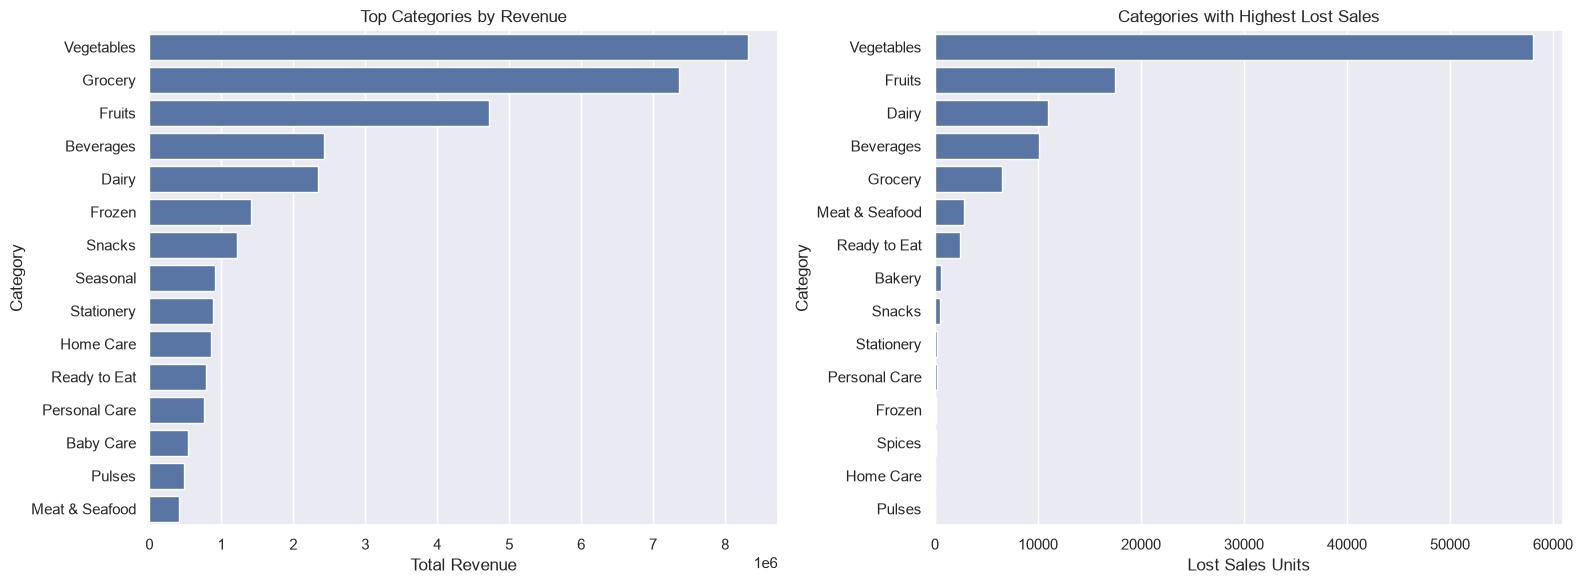

TOP 20 PRODUCTS BY REVENUE


,sku_id,product_name,revenue,units,lost_sales
1,SKU0002,Onion,1704021.10,42184,1231
46,SKU0047,Rice 5kg,1694220.62,4231,148
2,SKU0003,Potato,1422766.81,33801,9233
21,SKU0022,Apple,1295794.71,6158,1065
50,SKU0051,Cooking Oil 1L,964541.01,6498,519
51,SKU0052,Sunflower Oil 1L,857701.46,5808,17
31,SKU0032,Milk 1L,675064.64,10001,2292
17,SKU0018,Garlic,670491.66,3713,412
48,SKU0049,Toor Dal 1kg,631859.00,4525,77
44,SKU0045,Chocolate Ice Cream 500ml,631652.51,2734,6


PERISHABLE PRODUCT DISTRIBUTION


,is_perishable,total_products
0,False,53
1,True,47


In [21]:
# ==========================================
# PRODUCT AND CATEGORY ANALYSIS
# ==========================================

if not sales.empty and not products.empty:

    # Select the actual columns available in Dataset V2
    product_columns = [
        "sku_id",
        "product_name",
        "category",
        "subcategory",
        "is_perishable"
    ]

    product_sales = sales.merge(
        products[product_columns],
        on="sku_id",
        how="left",
        validate="many_to_one"
    )

    # Category-wise performance
    category_summary = product_sales.groupby(
        "category", dropna=False
    ).agg(
        revenue=("revenue", "sum"),
        fulfilled_units=("quantity", "sum"),
        demand_units=("demand_units", "sum"),
        lost_sales_units=("lost_sales_units", "sum"),
        sku_count=("sku_id", "nunique")
    ).reset_index()

    category_summary = category_summary.sort_values(
        "revenue", ascending=False
    )

    print("CATEGORY-WISE PERFORMANCE")
    display(category_summary)

    # Visualizations
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Revenue by category
    sns.barplot(
        data=category_summary.head(15),
        y="category",
        x="revenue",
        ax=axes[0]
    )

    axes[0].set_title("Top Categories by Revenue")
    axes[0].set_xlabel("Total Revenue")
    axes[0].set_ylabel("Category")

    # Lost sales by category
    lost_sales_summary = category_summary.sort_values(
        "lost_sales_units", ascending=False
    ).head(15)

    sns.barplot(
        data=lost_sales_summary,
        y="category",
        x="lost_sales_units",
        ax=axes[1]
    )

    axes[1].set_title("Categories with Highest Lost Sales")
    axes[1].set_xlabel("Lost Sales Units")
    axes[1].set_ylabel("Category")

    plt.tight_layout()
    plt.show()

    # Top-performing SKUs
    top_skus = product_sales.groupby(
        ["sku_id", "product_name"]
    ).agg(
        revenue=("revenue", "sum"),
        units=("quantity", "sum"),
        lost_sales=("lost_sales_units", "sum")
    ).reset_index()

    top_skus = top_skus.sort_values(
        "revenue", ascending=False
    )

    print("TOP 20 PRODUCTS BY REVENUE")
    display(top_skus.head(20))

    # Perishable vs non-perishable analysis
    print("PERISHABLE PRODUCT DISTRIBUTION")

    perishability = products.groupby(
        "is_perishable"
    ).agg(
        total_products=("sku_id", "nunique")
    ).reset_index()

    display(perishability)

## 6. Sales, demand and seasonality analysis

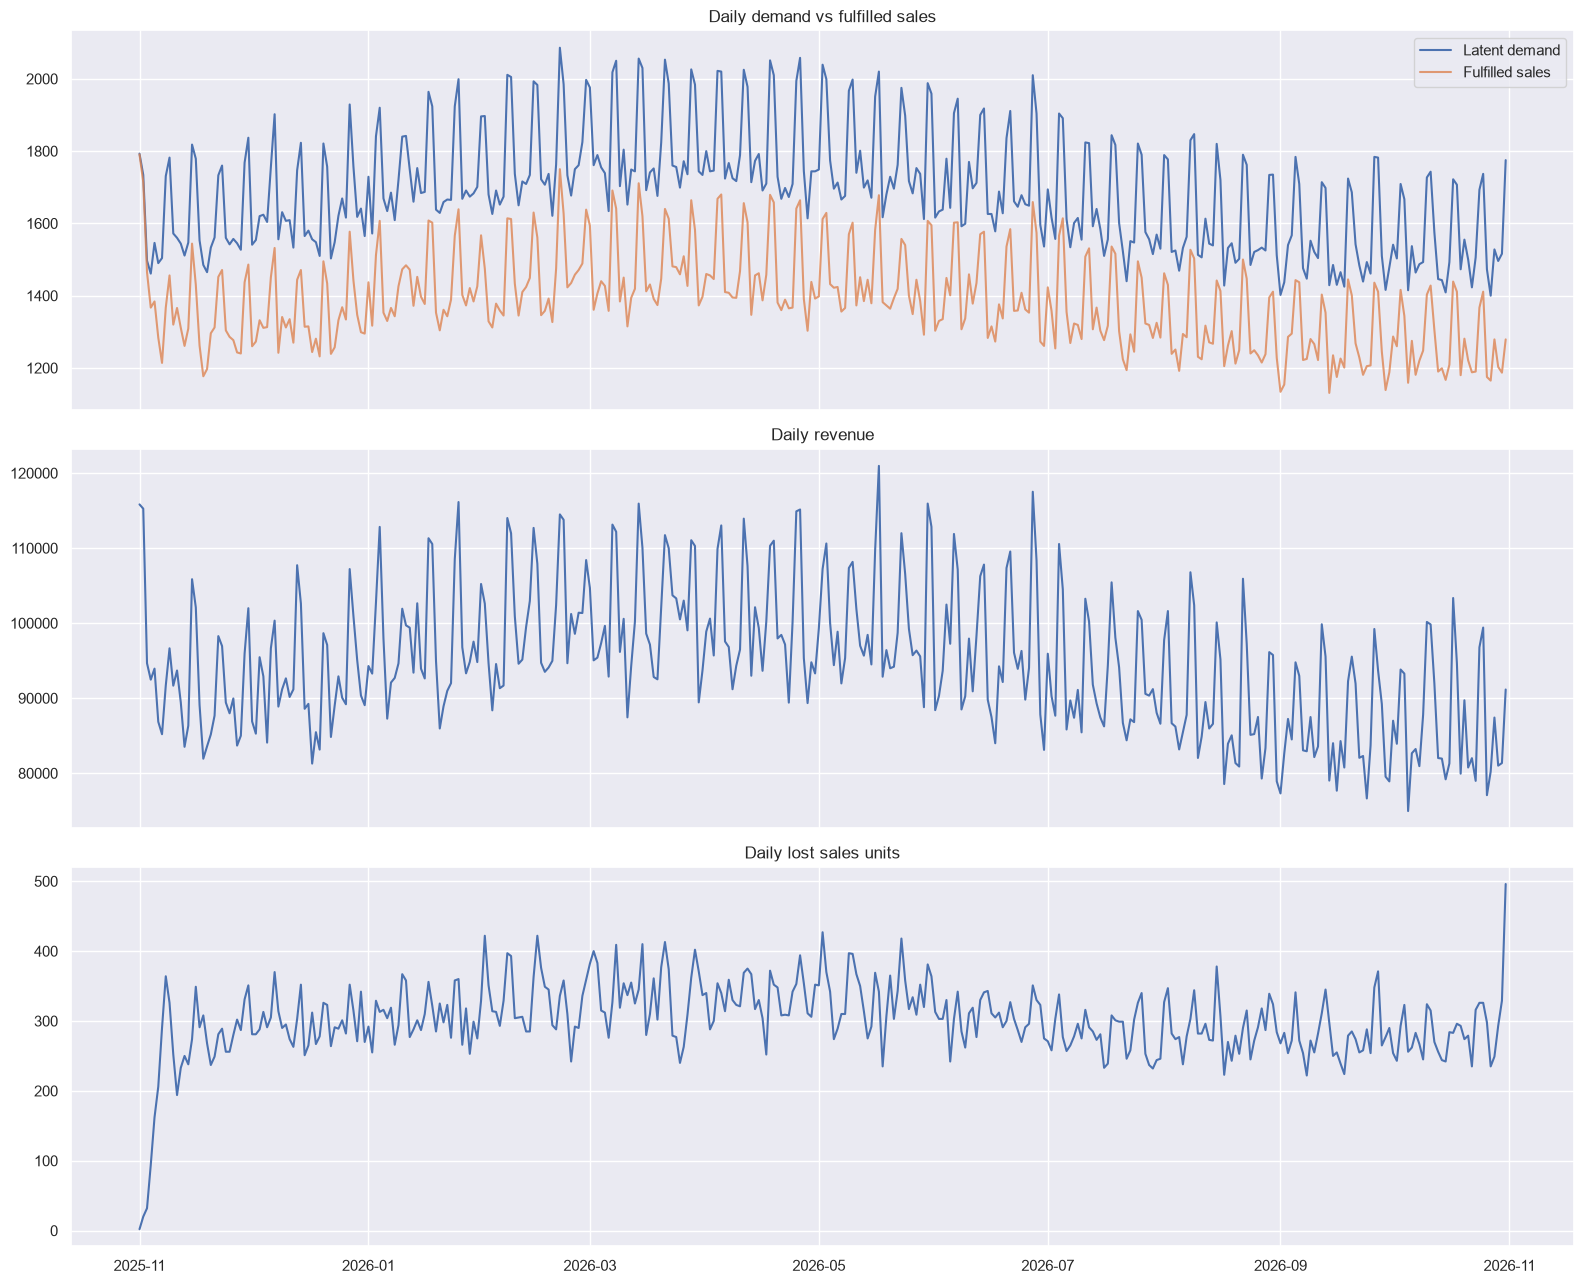

,weekday,demand,fulfilled,revenue
0,Monday,0.892872,0.731195,50.450596
1,Tuesday,0.887822,0.729118,49.872114
2,Wednesday,0.896857,0.737194,50.278904
3,Thursday,0.896218,0.738515,49.947844
4,Friday,0.895792,0.736469,50.373676
5,Saturday,1.039586,0.853217,58.455802
6,Sunday,1.035809,0.847976,57.913072


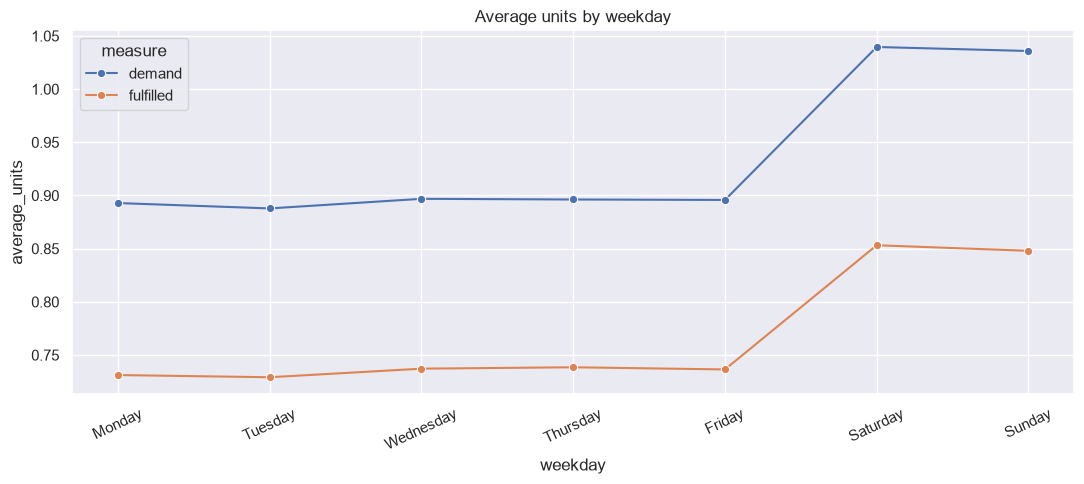

,month,demand,fulfilled,revenue
0,2025-11,48295,41023,2781810.20
1,2025-12,50911,41692,2858134.16
2,2026-01,53975,44456,3033214.52
3,2026-02,50122,40865,2816448.47
4,2026-03,56396,45890,3133857.32
5,2026-04,54174,44182,3011533.44
6,2026-05,55684,45203,3130607.29
7,2026-06,51573,42397,2902611.22
8,2026-07,50787,42160,2872518.26
9,2026-08,49729,40736,2766253.13


In [10]:
if not sales.empty:
    sales["date"] = pd.to_datetime(sales["date"])
    daily = sales.groupby("date").agg(
        fulfilled_units=("quantity", "sum"),
        demand_units=("demand_units", "sum"),
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum"),
        lost_sales_units=("lost_sales_units", "sum")
    ).reset_index().sort_values("date")

    fig, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=True)
    axes[0].plot(daily["date"], daily["demand_units"], label="Latent demand")
    axes[0].plot(daily["date"], daily["fulfilled_units"], label="Fulfilled sales", alpha=0.8)
    axes[0].set_title("Daily demand vs fulfilled sales")
    axes[0].legend()
    axes[1].plot(daily["date"], daily["revenue"])
    axes[1].set_title("Daily revenue")
    axes[2].plot(daily["date"], daily["lost_sales_units"])
    axes[2].set_title("Daily lost sales units")
    plt.tight_layout()
    plt.show()

    sales["weekday"] = sales["date"].dt.day_name()
    weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    weekday = sales.groupby("weekday").agg(
        demand=("demand_units", "mean"),
        fulfilled=("quantity", "mean"),
        revenue=("revenue", "mean")
    ).reindex(weekday_order).reset_index()
    display(weekday)

    fig, ax = plt.subplots(figsize=(11, 5))
    weekday_melt = weekday.melt(id_vars="weekday", value_vars=["demand", "fulfilled"],
                                var_name="measure", value_name="average_units")
    sns.lineplot(data=weekday_melt, x="weekday", y="average_units", hue="measure",
                 marker="o", ax=ax)
    ax.set_title("Average units by weekday")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

    monthly = sales.assign(month=sales["date"].dt.to_period("M").astype(str)).groupby("month").agg(
        demand=("demand_units", "sum"), fulfilled=("quantity", "sum"),
        revenue=("revenue", "sum")
    ).reset_index()
    display(monthly)

### 6.1 Demand censoring during stockouts

A key modelling issue: when stock is unavailable, fulfilled sales may understate true demand. Use `demand_units` as the target only if it is intentionally available as the synthetic ground-truth label. In a real deployment, true unconstrained demand is not directly observed and must be estimated.

In [11]:
if not sales.empty and {"demand_units", "quantity", "lost_sales_units"}.issubset(sales.columns):
    censoring = pd.DataFrame({
        "metric": ["Total latent demand", "Total fulfilled sales", "Total lost sales",
                   "Rows with lost sales", "Lost-sales share of latent demand"],
        "value": [
            sales["demand_units"].sum(),
            sales["quantity"].sum(),
            sales["lost_sales_units"].sum(),
            int((sales["lost_sales_units"] > 0).sum()),
            sales["lost_sales_units"].sum() / max(sales["demand_units"].sum(), 1)
        ]
    })
    display(censoring)

,metric,value
0,Total latent demand,616186.000000
1,Total fulfilled sales,505914.000000
2,Total lost sales,110272.000000
3,Rows with lost sales,60149.000000
4,Lost-sales share of latent demand,0.178959


## 7. Inventory, stockouts and availability

,metric,value
0,Stockout row count,60149.000000
1,Stockout row share,0.091297
2,Total lost sales units,110272.000000
3,Average lost sales per affected row,1.833314


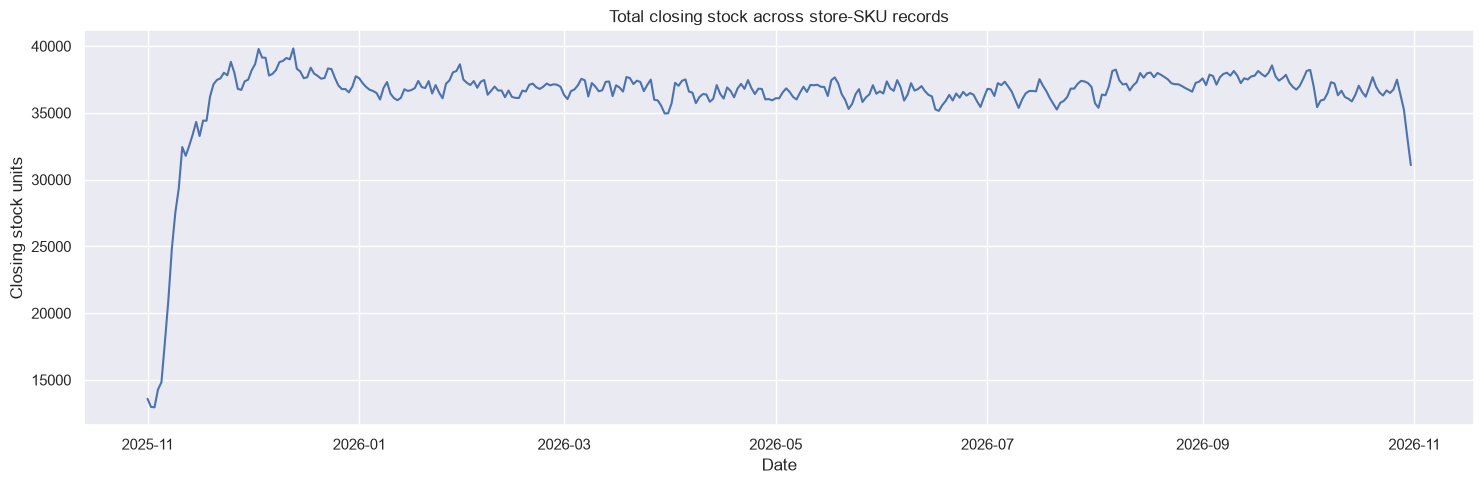

,snapshot_date,store_id,sku_id,on_hand_units,reserved_units,in_transit_units,reorder_point_units,target_stock_units,max_stock_units,days_of_cover_estimate,expiry_risk_flag
0,2026-10-31,ST001,SKU0001,16,1,0,9,19,39,5.71,True
1,2026-10-31,ST001,SKU0002,0,0,0,17,35,70,0.00,False
2,2026-10-31,ST001,SKU0003,5,0,0,17,35,70,1.00,False
3,2026-10-31,ST001,SKU0004,0,0,0,4,9,19,0.00,False
4,2026-10-31,ST001,SKU0005,0,0,0,3,8,15,0.00,False


Inventory columns: ['snapshot_date', 'store_id', 'sku_id', 'on_hand_units', 'reserved_units', 'in_transit_units', 'reorder_point_units', 'target_stock_units', 'max_stock_units', 'days_of_cover_estimate', 'expiry_risk_flag']


In [12]:
if not sales.empty:
    inventory_kpis = pd.DataFrame({
        "metric": ["Stockout row count", "Stockout row share",
                   "Total lost sales units", "Average lost sales per affected row"],
        "value": [
            int((sales["lost_sales_units"] > 0).sum()),
            float((sales["lost_sales_units"] > 0).mean()),
            float(sales["lost_sales_units"].sum()),
            float(sales.loc[sales["lost_sales_units"] > 0, "lost_sales_units"].mean())
        ]
    })
    display(inventory_kpis)

    if "closing_stock_units" in sales.columns:
        stock_by_day = sales.groupby("date")["closing_stock_units"].sum().reset_index()
        plt.figure(figsize=(15, 5))
        plt.plot(stock_by_day["date"], stock_by_day["closing_stock_units"])
        plt.title("Total closing stock across store-SKU records")
        plt.xlabel("Date")
        plt.ylabel("Closing stock units")
        plt.tight_layout()
        plt.show()

if not inventory.empty:
    display(inventory.head())
    print("Inventory columns:", inventory.columns.tolist())

## 8. Perishables and wastage analysis

In [13]:
if not products.empty:
    print("Perishable flag distribution:")
    if "perishable" in products.columns:
        display(products["perishable"].value_counts(dropna=False).to_frame("sku_count"))

if not wastage.empty:
    print("Wastage table columns:", wastage.columns.tolist())
    display(wastage.head())

    numeric_cols = wastage.select_dtypes(include=np.number).columns.tolist()
    print("Numeric wastage fields:", numeric_cols)

    date_col = next((c for c in ["date", "wastage_date"] if c in wastage.columns), None)
    if date_col:
        wastage[date_col] = pd.to_datetime(wastage[date_col])
        measure = next((c for c in ["wastage_units", "quantity", "units", "expired_units"] if c in wastage.columns), None)
        if measure:
            wastage_trend = wastage.groupby(wastage[date_col].dt.to_period("M"))[measure].sum()
            wastage_trend.index = wastage_trend.index.astype(str)
            plt.figure(figsize=(14, 5))
            wastage_trend.plot(kind="bar")
            plt.title(f"Monthly wastage trend ({measure})")
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

    # Join product category if compatible columns are present
    sku_col = next((c for c in ["sku_id", "product_id"] if c in wastage.columns), None)
    qty_col = next((c for c in ["wastage_units", "quantity", "units", "expired_units"] if c in wastage.columns), None)
    if sku_col and qty_col and "sku_id" in products.columns:
        w = wastage.merge(products[["sku_id", "category", "perishable"]], left_on=sku_col,
                          right_on="sku_id", how="left")
        display(w.groupby(["category", "perishable"], dropna=False)[qty_col].sum()
                .sort_values(ascending=False).to_frame("wastage_units"))

Perishable flag distribution:
Wastage table columns: ['date', 'store_id', 'sku_id', 'wastage_type', 'wasted_units', 'estimated_cost']


,date,store_id,sku_id,wastage_type,wasted_units,estimated_cost
0,2025-11-11,ST001,SKU0001,Expiry,7,32.06
1,2025-11-17,ST001,SKU0001,Expiry,21,96.18
2,2025-11-24,ST001,SKU0001,Expiry,20,91.60
3,2025-12-03,ST001,SKU0001,Expiry,22,100.76
4,2025-12-15,ST001,SKU0001,Expiry,10,45.80


Numeric wastage fields: ['wasted_units', 'estimated_cost']


## 9. Supplier performance and replenishment

Purchase order columns: ['po_id', 'store_id', 'sku_id', 'supplier_id', 'order_date', 'ordered_quantity', 'expected_arrival_date', 'actual_arrival_date', 'received_quantity', 'quality_rejected_units', 'status', 'base_lead_time_days', 'delay_days', 'supplier_reliability_at_order']


,po_id,store_id,sku_id,supplier_id,order_date,ordered_quantity,expected_arrival_date,actual_arrival_date,received_quantity,quality_rejected_units,status,base_lead_time_days,delay_days,supplier_reliability_at_order
0,PO0000001,ST001,SKU0001,SUP016,2025-11-02,33,2025-11-05,2025-11-05,33,0,Received,3,0,0.915
1,PO0000002,ST001,SKU0001,SUP013,2025-11-10,46,2025-11-11,2025-11-11,46,0,Received,1,0,0.871
2,PO0000003,ST001,SKU0001,SUP013,2025-11-17,46,2025-11-18,2025-11-18,46,0,Received,1,0,0.871
3,PO0000004,ST001,SKU0001,SUP016,2025-11-24,33,2025-11-27,2025-11-27,33,0,Received,3,0,0.915
4,PO0000005,ST001,SKU0001,SUP016,2025-12-03,33,2025-12-06,2025-12-09,33,0,Delayed,3,3,0.915


,status,count
0,Received,35929
1,Delayed,4184
2,Cancelled,489


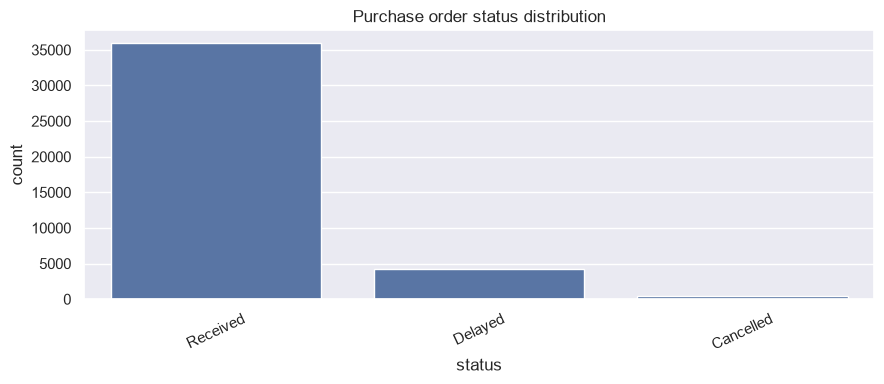

Goods receipt columns: ['receipt_id', 'po_id', 'store_id', 'sku_id', 'receipt_date', 'quantity_received', 'quality_rejected_units']


,receipt_id,po_id,store_id,sku_id,receipt_date,quantity_received,quality_rejected_units
0,RCV0000001,PO0000001,ST001,SKU0001,2025-11-05,33,0
1,RCV0000002,PO0000002,ST001,SKU0001,2025-11-11,46,0
2,RCV0000003,PO0000003,ST001,SKU0001,2025-11-18,46,0
3,RCV0000004,PO0000004,ST001,SKU0001,2025-11-27,33,0
4,RCV0000005,PO0000005,ST001,SKU0001,2025-12-09,33,0


Available PO date columns: ['order_date']


In [14]:
if not purchase_orders.empty:
    print("Purchase order columns:", purchase_orders.columns.tolist())
    display(purchase_orders.head())
    status_col = next((c for c in ["status", "po_status", "order_status"] if c in purchase_orders.columns), None)
    if status_col:
        status_counts = purchase_orders[status_col].value_counts(dropna=False).rename_axis("status").reset_index(name="count")
        display(status_counts)
        plt.figure(figsize=(9, 4))
        sns.barplot(data=status_counts, x="status", y="count")
        plt.title("Purchase order status distribution")
        plt.xticks(rotation=25)
        plt.tight_layout()
        plt.show()

if not goods_receipts.empty:
    print("Goods receipt columns:", goods_receipts.columns.tolist())
    display(goods_receipts.head())

# Lead-time analysis where order and receipt dates are available
if not purchase_orders.empty:
    date_candidates = ["order_date", "expected_delivery_date", "actual_delivery_date",
                       "received_date", "delivery_date"]
    print("Available PO date columns:", [c for c in date_candidates if c in purchase_orders.columns])

## 10. Promotions, pricing and competitor analysis

In [15]:
if not promotions.empty:
    print("Promotions columns:", promotions.columns.tolist())
    display(promotions.head())

if not sales.empty:
    possible_discount_col = next((c for c in ["discount_pct", "discount_percent", "discount"] if c in sales.columns), None)
    if possible_discount_col:
        discount_summary = sales.groupby(pd.cut(sales[possible_discount_col], bins=5, duplicates="drop")).agg(
            avg_demand=("demand_units", "mean"),
            avg_fulfilled=("quantity", "mean"),
            avg_revenue=("revenue", "mean"),
            row_count=("sku_id", "size")
        ).reset_index()
        display(discount_summary)

if not competitor_prices.empty:
    print("Competitor price columns:", competitor_prices.columns.tolist())
    display(competitor_prices.head())

if not price_history.empty:
    print("Price history columns:", price_history.columns.tolist())
    display(price_history.head())

Promotions columns: ['promotion_id', 'store_id', 'sku_id', 'promotion_type', 'discount_pct', 'start_date', 'end_date', 'campaign_budget']


,promotion_id,store_id,sku_id,promotion_type,discount_pct,start_date,end_date,campaign_budget
0,PR0001,ST012,SKU0051,Percentage Discount,0.139,2026-06-26,2026-07-04,6235.81
1,PR0002,ST009,SKU0071,Percentage Discount,0.249,2026-09-26,2026-10-07,5209.71
2,PR0003,ST014,SKU0006,Percentage Discount,0.142,2026-06-25,2026-07-03,2851.94
3,PR0004,ST013,SKU0037,Percentage Discount,0.054,2025-12-10,2025-12-23,4409.31
4,PR0005,ST008,SKU0079,Clearance,0.140,2026-06-23,2026-07-05,7067.85


,discount_pct,avg_demand,avg_fulfilled,avg_revenue,row_count
0,"(-0.00028, 0.056]",0.934793,0.767482,52.475920,656690
1,"(0.056, 0.112]",1.351171,1.118729,59.881371,598
2,"(0.112, 0.168]",1.047970,0.911439,59.331900,542
3,"(0.168, 0.224]",0.791111,0.615556,45.102800,450
4,"(0.224, 0.28]",1.073394,0.873394,56.633413,545


Competitor price columns: ['date', 'location', 'sku_id', 'competitor_id', 'competitor_price', 'our_reference_price']


,date,location,sku_id,competitor_id,competitor_price,our_reference_price
0,2025-11-01,Bangalore,SKU0001,CMP-BAN,6.66,6.54
1,2025-11-02,Bangalore,SKU0001,CMP-BAN,6.67,6.54
2,2025-11-03,Bangalore,SKU0001,CMP-BAN,6.72,6.54
3,2025-11-04,Bangalore,SKU0001,CMP-BAN,6.66,6.54
4,2025-11-05,Bangalore,SKU0001,CMP-BAN,6.71,6.54


Price history columns: ['date', 'location', 'sku_id', 'regular_price', 'selling_price', 'markdown_pct']


,date,location,sku_id,regular_price,selling_price,markdown_pct
0,2025-11-01,Bangalore,SKU0001,6.54,6.54,0.0
1,2025-11-08,Bangalore,SKU0001,6.54,6.54,0.0
2,2025-11-15,Bangalore,SKU0001,6.54,6.54,0.0
3,2025-11-22,Bangalore,SKU0001,6.54,6.54,0.0
4,2025-11-29,Bangalore,SKU0001,6.54,6.54,0.0


## 11. Weather, events and external signal analysis

In [16]:
for label, df in [("Weather", weather), ("Events", events), ("News", news)]:
    print(f"\n{label}: {df.shape}")
    if not df.empty:
        display(df.head(3))
        print("Columns:", df.columns.tolist())

# Weather-demand relationship: exploratory association only, not causal evidence.
if not weather.empty and not sales.empty and {"date", "store_id"}.issubset(weather.columns):
    join_cols = ["date", "store_id"]
    available_weather_cols = [c for c in weather.columns if c not in sales.columns or c in join_cols]
    wx = sales.merge(weather[available_weather_cols], on=join_cols, how="left")
    numeric_weather = [c for c in wx.select_dtypes(include=np.number).columns
                       if c not in ["quantity", "demand_units", "revenue", "gross_profit"]]
    if numeric_weather:
        display(wx[["demand_units", "quantity"] + numeric_weather].corr(numeric_only=True)
                .iloc[:2, :].T)


Weather: (1095, 7)


,date,location,temperature_c,rainfall_mm,weather_condition,forecast_temperature_c,forecast_rainfall_mm
0,2025-11-01,Bangalore,25.2,2.1,Cloudy,25.2,0.0
1,2025-11-02,Bangalore,23.9,0.9,Clear,24.9,1.8
2,2025-11-03,Bangalore,21.7,2.0,Cloudy,24.2,1.4


Columns: ['date', 'location', 'temperature_c', 'rainfall_mm', 'weather_condition', 'forecast_temperature_c', 'forecast_rainfall_mm']

Events: (33, 8)


,event_id,location,event_type,event_date,expected_footfall,impact_index,affected_categories,event_radius_km
0,EV0001,Bangalore,Public Holiday,2025-12-25,3930,1.12,Beverages;Snacks;Bakery,7.8
1,EV0002,Bangalore,Festival,2026-01-14,5399,1.25,Seasonal;Grocery;Snacks,5.2
2,EV0003,Bangalore,Public Holiday,2026-08-15,2462,1.12,Beverages;Snacks;Bakery,5.2


Columns: ['event_id', 'location', 'event_type', 'event_date', 'expected_footfall', 'impact_index', 'affected_categories', 'event_radius_km']

News: (105, 16)


,news_id,published_at,location,headline,source,url,category,event_type,affected_categories,relevance_score,demand_impact_direction,simulated_uplift_factor,confidence,verification_status,deduplication_key,impact_window_days
0,NWS00001,2025-11-18 18:00:00+05:30,Bangalore,Transport disruption reported in Bangalore,SIMULATED_NEWS_SOURCE,synthetic://news/NWS00001,Transport,Transport Disruption,All,0.71,Negative,0.96,0.71,Synthetic simulation; not a live article,bangalore|transport disruption|2025-11-18,3
1,NWS00002,2025-12-07 18:00:00+05:30,Bangalore,Large public gathering planned in Bangalore,SIMULATED_NEWS_SOURCE,synthetic://news/NWS00002,Events,Major Event,Beverages;Snacks;Ready to Eat,0.82,Positive,1.08,0.74,Synthetic simulation; not a live article,bangalore|major event|2025-12-07,3
2,NWS00003,2025-12-10 18:00:00+05:30,Bangalore,Heatwave advisory for Bangalore,SIMULATED_NEWS_SOURCE,synthetic://news/NWS00003,Weather,Heatwave,Beverages;Frozen,0.75,Positive,1.12,0.89,Synthetic simulation; not a live article,bangalore|heatwave|2025-12-10,3


Columns: ['news_id', 'published_at', 'location', 'headline', 'source', 'url', 'category', 'event_type', 'affected_categories', 'relevance_score', 'demand_impact_direction', 'simulated_uplift_factor', 'confidence', 'verification_status', 'deduplication_key', 'impact_window_days']


### 11.1 News signal quality checks

In [17]:
if not news.empty:
    print("Synthetic news signals are contextual features, not verified real-world causal evidence.")
    display(news.isna().mean().mul(100).sort_values(ascending=False).rename("missing_pct").to_frame())
    for col in ["city", "location", "event_type", "category", "source"]:
        if col in news.columns:
            print(f"\n{col} distribution:")
            display(news[col].value_counts(dropna=False).head(15).to_frame("count"))

    if "published_at" in news.columns:
        news["published_at"] = pd.to_datetime(news["published_at"], errors="coerce")
        print("News publication date range:", news["published_at"].min(), "to", news["published_at"].max())

Synthetic news signals are contextual features, not verified real-world causal evidence.


,missing_pct
news_id,0.0
published_at,0.0
location,0.0
headline,0.0
source,0.0
url,0.0
category,0.0
event_type,0.0
affected_categories,0.0
relevance_score,0.0



location distribution:


,count
location,
Bangalore,35
Chennai,35
Coimbatore,35



event_type distribution:


,count
event_type,
Transport Disruption,23
Major Event,18
Market Disruption,14
Festival,14
Heavy Rain,14
School Reopening,13
Heatwave,9



category distribution:


,count
category,
Transport,23
Weather,23
Events,18
Business,14
Community,14
Education,13



source distribution:


,count
source,
SIMULATED_NEWS_SOURCE,105


News publication date range: 2025-11-07 18:00:00+05:30 to 2026-10-28 18:00:00+05:30


## 12. Correlation and relationship exploration

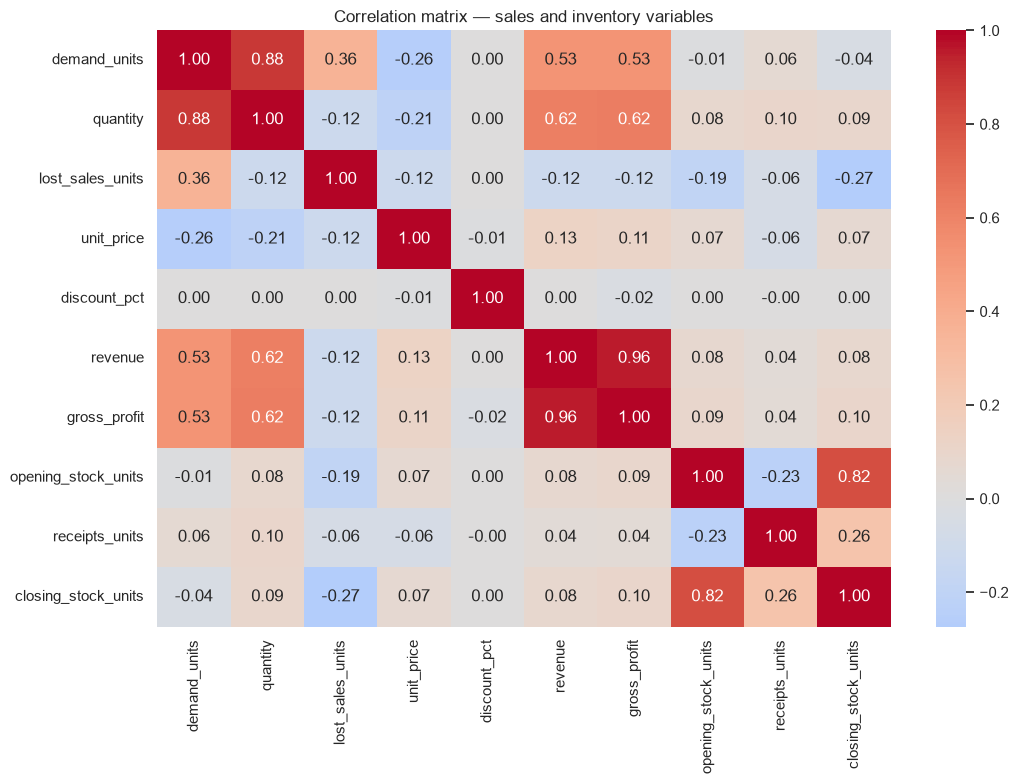

In [18]:
if not sales.empty:
    numeric = sales.select_dtypes(include=np.number)
    selected = [c for c in [
        "demand_units", "quantity", "lost_sales_units", "unit_price",
        "discount_pct", "revenue", "gross_profit", "opening_stock_units",
        "receipts_units", "closing_stock_units", "expired_units"
    ] if c in numeric.columns]
    if len(selected) >= 2:
        corr = sales[selected].corr()
        plt.figure(figsize=(11, 8))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
        plt.title("Correlation matrix — sales and inventory variables")
        plt.tight_layout()
        plt.show()

## 13. Chronological train / validation / test split review

In [19]:
for split_name in ["train", "validation", "test"]:
    split_file = DATA_DIR / f"evaluation/{split_name}_sales_daily.csv"
    if split_file.exists():
        tmp = pd.read_csv(split_file, parse_dates=["date"])
        print(f"{split_name:10s} rows={len(tmp):,} | "
              f"{tmp['date'].min().date()} to {tmp['date'].max().date()}")

if not split_manifest.empty:
    display(split_manifest)

print("\nModelling rule: use train for fitting, validation for model selection, and test only once for final unbiased evaluation.")

,split,start_date,end_date,purpose
0,train,2025-11-01,2026-07-31,Fit models and transformations
1,validation,2026-08-01,2026-09-30,Tune model and thresholds
2,test,2026-10-01,2026-10-31,Untouched final holdout



Modelling rule: use train for fitting, validation for model selection, and test only once for final unbiased evaluation.


## 14. Surprise scenarios and baseline policy review

In [20]:
if not scenarios.empty:
    print("Surprise scenario columns:", scenarios.columns.tolist())
    display(scenarios)

if not baseline_policies.empty:
    print("Baseline policy columns:", baseline_policies.columns.tolist())
    display(baseline_policies)

Surprise scenario columns: ['scenario_id', 'location', 'scenario_type', 'target_entity', 'injected_change', 'expected_system_response']


,scenario_id,location,scenario_type,target_entity,injected_change,expected_system_response
0,SC001,Chennai,Supplier Failure,SUP003,supplier_reliability=0; delay open orders by 7...,"Compare alternate supplier, transfers and lost..."
1,SC002,Bangalore,Demand Spike,SKU0001,demand_multiplier=1.60; duration_days=5,Reforecast tomato demand and evaluate transfer...
2,SC003,Coimbatore,Heavy Rain,ALL,rainfall_mm=60; delivery_delay_multiplier=1.5,Recalculate category demand and inbound logist...
3,SC004,Chennai,Competitor Discount,SKU0038,competitor_price_multiplier=0.75; duration_days=7,"Assess elasticity, margin floor and promotion ..."
4,SC005,Bangalore,News Event,STORE_CATCHMENT,event_footfall_multiplier=2; duration_days=2,Map event radius to stores and relevant catego...
5,SC006,Coimbatore,Cold Chain Failure,PERISHABLES,cold_chain_status=failed; duration_hours=8,Identify perishables and minimize spoilage safely
6,SC007,All,Store Closure,ST006,store_status=closed; duration_days=2,Reallocate demand and stock to nearby stores
7,SC008,All,Demand Collapse,CATEGORY:Seasonal,demand_multiplier=.55; duration_days=14,Avoid overstock and evaluate markdown decisions


Baseline policy columns: ['baseline_id', 'baseline_name', 'policy_definition', 'benchmark_role']


,baseline_id,baseline_name,policy_definition,benchmark_role
0,B0,Fixed Reorder Point,Order to target when inventory position <= reo...,Inventory baseline
1,B1,Seasonal Naive,Use previous week's same weekday demand,Forecast baseline
2,B2,ML Without News,"Sales lags, calendar, weather, promotions and ...",News ablation
3,B3,News-Aware Model,Validated lagged news and event features added...,Candidate model
4,B4,Cost-Based Decision Policy,Choose feasible action minimizing expected tot...,Decision baseline


## 15. EDA findings — complete after running the notebook

Use this section to record findings from the actual outputs. Do not invent conclusions before inspecting the charts and tables.

### Data quality
- [ ] Primary keys and foreign keys are valid.
- [ ] Missing values are understood and handled.
- [ ] Stock-flow arithmetic has been rechecked.
- [ ] Dates and split boundaries are correct.

### Retail patterns
- [ ] Highest-revenue cities and stores identified.
- [ ] Fast-moving and slow-moving SKUs identified.
- [ ] Weekday/weekend and seasonal patterns identified.
- [ ] Stockout and lost-sales hotspots identified.
- [ ] Perishable wastage hotspots identified.

### External signals
- [ ] Weather and event fields inspected.
- [ ] News signals checked for location, freshness and duplicates.
- [ ] Signal-to-demand relationships treated as associations, not assumed causation.

### Modelling readiness
- [ ] Forecast target selected and justified.
- [ ] Leakage risks reviewed.
- [ ] Baseline forecasting approach documented.
- [ ] Test set kept untouched until final evaluation.

## 16. Recommended next notebook

After EDA, create **02_Retail_Feature_Engineering_and_Forecasting.ipynb**:
1. Define forecasting grain (store × SKU × date).
2. Build calendar and lag features.
3. Add rolling statistics using past data only.
4. Encode promotions, weather and events.
5. Train a naive baseline and a tree-based model.
6. Evaluate by city, store, category and SKU.
7. Compare performance on normal-demand and stockout periods.